<a href="https://colab.research.google.com/github/sankeawthong/Project-1-Lita-Chatbot/blob/main/Lab14_DQN_CartPole%20and%20practice%20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 14 — DQN on CartPole: evaluating RL agents

**Machine Learning · Week 14**

| | |
|---|---|
| **Time budget** | ~2 hours (in-lab) |
| **Learning objectives** | 1. Evaluate an agent honestly: four measures and a separate greedy test — 2. See why a Q-table fails on a continuous state — 3. Train a Deep Q-Network from a template (replay buffer + target network) — 4. Compare Q-learning and DQN — 5. Plot and read reward curves over several seeds |
| **Environment** | `CartPole-v1` (balance the pole; +1 per step; max 500) |
| **Tools** | Gymnasium · PyTorch (CPU only — no GPU needed) |
| **Grading** | Exercises 1–6 + AI-usage disclosure · self-checks give instant feedback |

> **The story.** Week 13 ended with a promise: when the table is too big, use a function. Today we keep it — and we check whether it really worked. Every number matches the Week 14 lecture: random **22**, angle rule **42**, Q-table test **99** (seed 0) although its training curve "solved" the task, DQN **500** after about **174** episodes, and an agent **worse than random** without its target network.
>
> Each part starts with a **predict before you run** line. Write one sentence before you run the cell.

**Textbook:** Géron (2nd ed.), Ch. 18 — Deep Q-Learning (Eq. 18-7), catastrophic forgetting and instability, fixed Q-value targets.

**Run time:** Restart-and-run-all takes about 8–10 minutes on Colab's free CPU (each DQN run 1–2 minutes). **Your numbers may differ slightly** from the lecture if your PyTorch version or CPU is different — the conclusions will not.

**First:** File → Save a copy in Drive, rename to `Lab14_<your_student_id>`.

---
## Setup

In [1]:
try:
    import gymnasium as gym
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gymnasium"], check=True)
    import gymnasium as gym
import random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
torch.set_num_threads(1)          # same speed and results on every laptop and on Colab
print("Gymnasium", gym.__version__, "· PyTorch", torch.__version__, "· setup complete ✔")

Gymnasium 1.4.0 · PyTorch 2.14.1+cpu · setup complete ✔


### The evaluation tools (used in every part)

| helper | what it does |
|---|---|
| `evaluate(policy, n=100)` | the **exam**: plays `n` **new** episodes (seeds the agent never trained on) with the policy as it is now — no exploring — and reports mean, spread, min and how many reached 475 |
| `moving(x, w)` | moving average of the last `w` episodes (smooths a noisy learning curve) |
| `first_at_or_above(curve, level, w)` | the first episode where the `w`-episode average reaches `level` — **convergence speed** |

In [2]:
def evaluate(policy, n=100, seed=10**6):
    """Greedy test: n NEW episodes. policy(state) -> action."""
    env = gym.make("CartPole-v1"); R = []
    for ep in range(n):
        s, _ = env.reset(seed=seed + ep); G, done = 0.0, False
        while not done:
            s, r, terminated, truncated, _ = env.step(policy(s)); G += r; done = terminated or truncated
        R.append(G)
    R = np.array(R)
    return {"mean": float(round(R.mean(), 2)), "std": float(round(R.std(), 2)), "min": int(R.min()), "reached 475": f"{(R >= 475).mean():.0%}"}

def moving(x, w=20):
    x = np.asarray(x, float)
    return np.convolve(x, np.ones(w) / w, mode="valid")

def first_at_or_above(curve, level=475, w=20):
    m = moving(curve, w); hit = np.flatnonzero(m >= level)
    return int(hit[0] + w) if len(hit) else None

print("evaluation tools ready ✔")

evaluation tools ready ✔


---
## Part 1 · CartPole and two baselines

The state is four numbers: **cart position, cart velocity, pole angle, pole angular velocity**. Actions: **0 = push left, 1 = push right**. Reward +1 for every step the pole stays up; the episode ends when the pole falls (*terminated*) or after 500 steps (*truncated*).

Before any learning, measure what you must beat: a **random** agent and Géron's hand-written **angle rule** — push towards the side the pole is leaning.

> **Predict before you run.** How many steps will the random agent last on average? Will the simple angle rule double it?
>
> *My prediction:* …

In [3]:
rng_base = np.random.default_rng(0)
random_policy = lambda s: int(rng_base.integers(2))
angle_rule    = lambda s: 1 if s[2] > 0 else 0        # s[2] = pole angle: leaning right -> push right

baselines = pd.DataFrame({"random": evaluate(random_policy), "angle rule": evaluate(angle_rule)}).T
baselines

,mean,std,min,reached 475
random,22.52,10.73,9,0%
angle rule,42.58,9.07,25,0%


**What to notice:** random ≈ **22**, the angle rule ≈ **42** (Géron reports 41.7). Both are far from the target of **475**. Any learning curve you draw today needs these two lines on it — a number without a baseline can't be judged.

---
## Part 2 · The Q-table — and the "solved" trap

Week 13's Q-learning needs **discrete** states, so we chop each of the four numbers into **10 bins**: 10⁴ = 10,000 states × 2 actions = **20,000** table entries.

In [4]:
LOW, HIGH = np.array([-2.4, -3.0, -0.21, -3.5]), np.array([2.4, 3.0, 0.21, 3.5])
EDGES = [np.linspace(LOW[i], HIGH[i], 11)[1:-1] for i in range(4)]
def to_bin(s):                                         # 4 numbers -> one state number 0 … 9,999
    idx = [int(np.digitize(s[i], EDGES[i])) for i in range(4)]
    return idx[0] + 10 * idx[1] + 100 * idx[2] + 1000 * idx[3]

def q_table_cartpole(episodes, seed=0, alpha=0.1, gamma=0.99):
    env = gym.make("CartPole-v1"); Q = np.zeros((10_000, 2)); rng = np.random.default_rng(seed); R = []
    for ep in range(episodes):
        eps = max(0.05, 1 - ep / (0.6 * episodes))
        s, _ = env.reset(seed=seed * 100000 + ep); x = to_bin(s); G, done = 0.0, False
        while not done:
            if rng.random() < eps: a = int(rng.integers(2))
            else: a = int(rng.choice(np.flatnonzero(Q[x] == Q[x].max())))
            s, r, terminated, truncated, _ = env.step(a); x2 = to_bin(s)
            Q[x, a] += alpha * (r + (0 if terminated else gamma * Q[x2].max()) - Q[x, a])   # Week 13's update
            x = x2; G += r; done = terminated or truncated
        R.append(G)
    rng_e = np.random.default_rng(0)
    policy = lambda s: int(rng_e.choice(np.flatnonzero(Q[to_bin(s)] == Q[to_bin(s)].max())))
    return {"Q": Q, "returns": np.array(R), "policy": policy}
print("Q-table tools ready ✔")

Q-table tools ready ✔


> **Predict before you run.** After 5,000 episodes the training curve will pass 475. Will the greedy **test** also be near 475?
>
> *My prediction:* …

In [5]:
t0 = time.time()
tab = q_table_cartpole(5000, seed=0)                   # ≈ 40 s
tab_test = evaluate(tab["policy"])
visited = int((np.abs(tab["Q"]).sum(1) > 0).sum())
print(f"trained in {time.time() - t0:.0f} s · training average reached 475 at episode {first_at_or_above(tab['returns'])}")
print(f"states ever visited: {visited:,} of 10,000 ({visited / 100:.0f}%)")
print("greedy test on 100 new episodes:", tab_test)

trained in 87 s · training average reached 475 at episode 3689
states ever visited: 1,604 of 10,000 (16%)
greedy test on 100 new episodes: {'mean': 99.39, 'std': 59.17, 'min': 47, 'reached 475': '0%'}


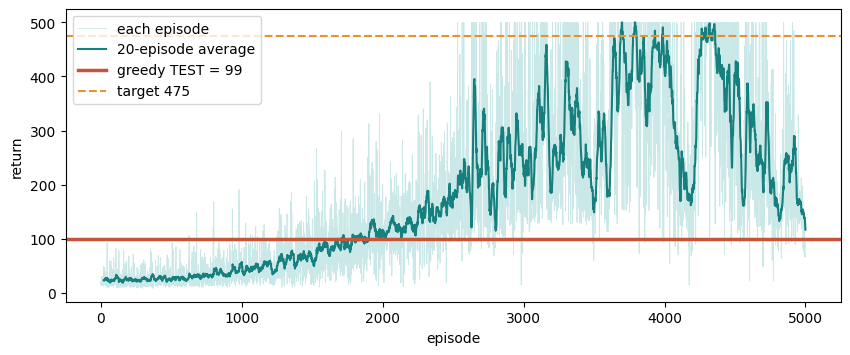

In [6]:
plt.figure(figsize=(10, 3.8))
plt.plot(tab["returns"], color="#2CA6A4", alpha=.25, lw=.6, label="each episode")
plt.plot(np.arange(20, 5001), moving(tab["returns"]), color="#15807E", lw=1.5, label="20-episode average")
plt.axhline(tab_test["mean"], color="#C4553B", lw=2.5, label=f"greedy TEST = {tab_test['mean']:.0f}")
plt.axhline(475, color="#E8912D", ls="--", label="target 475"); plt.xlabel("episode"); plt.ylabel("return"); plt.legend(loc="upper left"); plt.show()

**What to notice:** the training average passes 475 (around episode **3,689**), yet the greedy test is only about **99**. The table visited only about **16%** of its states — new starting states land in cells it never learned — and the 20-episode average picks a lucky stretch. **A training curve is a diary of the learning, not an exam.** (Lecture slides 7 and 12.)

---
## Part 3 · The DQN template

A **Deep Q-Network** replaces the table with a network: 4 inputs → 128 → 128 → 2 outputs, one Q-value per action. Everything else is Week 13's Q-learning, plus two stabilisers:

| piece | what it does | Géron |
|---|---|---|
| `QNet` | state → [Q(s, left), Q(s, right)] | p. 634 |
| `ReplayBuffer` | stores every step; `sample()` returns a **random** batch | p. 635 |
| `dqn_target` | **y = r + γ · max Q_target(s′, ·) × (1 − terminated)** — Eq. 18-7 | p. 634 |
| `soft_update` | target ← (1 − τ) · target + τ · online — a slow copy that computes the targets | p. 639 |
| `train_dqn` | the eight-line loop from lecture slide 20, with early stopping at a 475 average | p. 637 |

You will rewrite `dqn_target`, `ReplayBuffer.sample` and `soft_update` yourself in Exercises 1–3.

In [7]:
class QNet(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.f = nn.Sequential(nn.Linear(4, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, 2))
    def forward(self, x): return self.f(x)

class ReplayBuffer:
    def __init__(self, capacity=10_000):
        self.S  = np.zeros((capacity, 4), np.float32); self.A = np.zeros(capacity, np.int64); self.R = np.zeros(capacity, np.float32)
        self.S2 = np.zeros((capacity, 4), np.float32); self.D = np.zeros(capacity, np.float32)
        self.capacity, self.n, self.ptr = capacity, 0, 0
    def add(self, s, a, r, s2, terminated):           # overwrite the oldest step when full
        self.S[self.ptr], self.A[self.ptr], self.R[self.ptr], self.S2[self.ptr], self.D[self.ptr] = s, a, r, s2, float(terminated)
        self.ptr = (self.ptr + 1) % self.capacity; self.n = min(self.n + 1, self.capacity)
    def __len__(self): return self.n
    def sample(self, batch_size, rng):                # a RANDOM batch -> five tensors
        idx = rng.integers(self.n, size=batch_size)
        return (torch.as_tensor(self.S[idx]), torch.as_tensor(self.A[idx]), torch.as_tensor(self.R[idx]),
                torch.as_tensor(self.S2[idx]), torch.as_tensor(self.D[idx]))

def dqn_target(r, s2, terminated, target_net, gamma=0.99):
    with torch.no_grad():
        return r + gamma * (1 - terminated) * target_net(s2).max(1).values

def soft_update(target_net, online_net, tau=0.005):
    with torch.no_grad():
        for pt, po in zip(target_net.parameters(), online_net.parameters()):
            pt.mul_(1 - tau).add_(tau * po)

def train_dqn(seed=0, episodes=500, stop_avg=475, use_target=True, buffer_size=10_000, batch=128, lr=5e-4, gamma=0.99, hidden=128,
              target_fn=dqn_target, update_fn=soft_update, verbose=True):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    env = gym.make("CartPole-v1"); rng = np.random.default_rng(seed)
    online, target = QNet(hidden), QNet(hidden); target.load_state_dict(online.state_dict())
    opt = torch.optim.AdamW(online.parameters(), lr=lr, amsgrad=True); huber = nn.SmoothL1Loss()
    buf = ReplayBuffer(buffer_size); step = 0; returns, losses, q_start = [], [], []; t0 = time.time()
    for ep in range(episodes):
        s, _ = env.reset(seed=seed * 100000 + ep); G, done, ep_loss = 0.0, False, []
        while not done:
            eps = 0.05 + 0.85 * np.exp(-step / 1000)                              # ε: 0.9 -> 0.05
            if rng.random() < eps: a = int(rng.integers(2))                       # 1 · ε-greedy
            else:
                with torch.no_grad(): a = int(online(torch.as_tensor(s, dtype=torch.float32)).argmax())
            s2, r, terminated, truncated, _ = env.step(a); done = terminated or truncated   # 2 · step
            buf.add(s, a, r, s2, terminated); s = s2; G += r; step += 1                    # 3 · store
            if len(buf) >= batch:
                S, A, Rb, S2, D = buf.sample(batch, rng)                                   # 4 · random batch
                y = target_fn(Rb, S2, D, target if use_target else online, gamma)          # 5 · target (Eq. 18-7)
                q_sa = online(S).gather(1, A.unsqueeze(1)).squeeze(1)
                loss = huber(q_sa, y)                                                      # 6 · loss
                opt.zero_grad(); loss.backward(); nn.utils.clip_grad_value_(online.parameters(), 100); opt.step()   # 7 · learn
                if use_target: update_fn(target, online)                                   # 8 · slow copy
                ep_loss.append(loss.item())
        returns.append(G); losses.append(np.mean(ep_loss) if ep_loss else np.nan)
        if stop_avg and len(returns) >= 20 and np.mean(returns[-20:]) >= stop_avg: break  # keep the agent that reached the target
        with torch.no_grad(): q_start.append(float(online(torch.zeros(1, 4)).max()))
        if verbose and (ep + 1) % 50 == 0: print(f"  episode {ep + 1:4d} · 20-ep average {np.mean(returns[-20:]):6.1f} · {time.time() - t0:5.0f} s")
    policy = lambda x: int(online(torch.as_tensor(x, dtype=torch.float32)).argmax())
    return {"net": online, "policy": policy, "returns": np.array(returns), "losses": np.array(losses), "q_start": np.array(q_start),
            "steps": step, "seconds": round(time.time() - t0), "weights": sum(p.numel() for p in online.parameters())}
print("DQN template ready ✔")

DQN template ready ✔


> **Predict before you run.** How many episodes will the DQN need to reach a 475 average — more or fewer than the Q-table's 3,689?
>
> *My prediction:* …

In [8]:
dqn0 = train_dqn(seed=0)                               # ≈ 1 minute on a CPU
with torch.no_grad(): dqn0_test = evaluate(dqn0["policy"])
print(f"\nreached a 475 average at episode {len(dqn0['returns'])} · {dqn0['steps']:,} steps · {dqn0['seconds']} s · {dqn0['weights']:,} weights")
print("greedy test on 100 new episodes:", dqn0_test)

  episode   50 · 20-ep average   18.1 ·     3 s
  episode  100 · 20-ep average  183.4 ·    26 s
  episode  150 · 20-ep average  185.3 ·    53 s
  episode  200 · 20-ep average  439.8 ·   102 s

reached a 475 average at episode 207 · 41,287 steps · 112 s · 17,410 weights
greedy test on 100 new episodes: {'mean': 499.71, 'std': 2.79, 'min': 472, 'reached 475': '99%'}


**What to notice:** about **174** episodes (≈ **36,000** steps) instead of thousands, and a test of **500** — the full episode, every time. The network has **17,410** weights — about as many numbers as the table's 20,000 — but every state **shares** them, so what it learns at angle 0.03 also teaches it about angle 0.04.

---
## Part 4 · Q-table vs DQN — the four measures

| measure | question it answers |
|---|---|
| **cumulative reward** (mean training return) | how much did learning cost? |
| **convergence speed** | how many episodes / steps until the 20-episode average reached 475? |
| **stability** | spread of test results (here within one run; over seeds in Part 5) |
| **final performance** | the greedy test on 100 new episodes — the exam |

> **Predict before you run.** Which measure will show the biggest difference between the Q-table and DQN?
>
> *My prediction:* …

In [9]:
compare = pd.DataFrame({
    "Q-table (5,000 episodes)": {"episodes trained": len(tab["returns"]), "environment steps": int(tab["returns"].sum()),
        "mean training return": round(tab["returns"].mean(), 1), "episodes to 475 (training)": first_at_or_above(tab["returns"]),
        "test mean": tab_test["mean"], "test std": tab_test["std"], "test min": tab_test["min"]},
    "DQN (seed 0)": {"episodes trained": len(dqn0["returns"]), "environment steps": dqn0["steps"],
        "mean training return": round(dqn0["returns"].mean(), 1), "episodes to 475 (training)": first_at_or_above(dqn0["returns"]),
        "test mean": dqn0_test["mean"], "test std": dqn0_test["std"], "test min": dqn0_test["min"]}})
compare

,"Q-table (5,000 episodes)",DQN (seed 0)
episodes trained,5000.00,207.00
environment steps,916950.00,41287.00
mean training return,183.40,199.50
episodes to 475 (training),3689.00,207.00
test mean,99.39,499.71
test std,59.17,2.79
test min,47.00,472.00


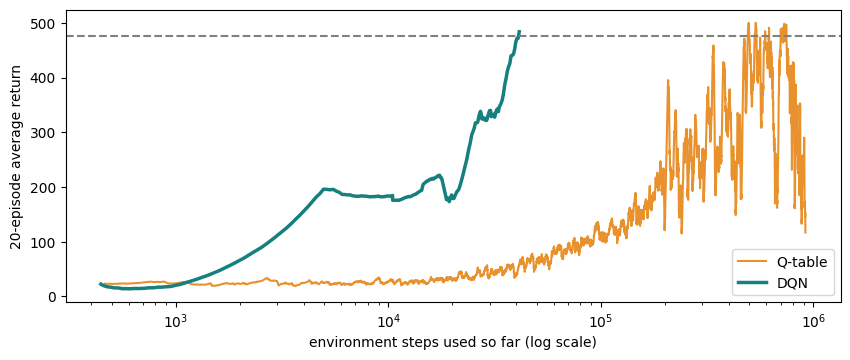

In [10]:
plt.figure(figsize=(10, 3.8))
plt.plot(np.cumsum(tab["returns"])[19:], moving(tab["returns"]), color="#E8912D", label="Q-table")
plt.plot(np.cumsum(dqn0["returns"])[19:], moving(dqn0["returns"]), color="#15807E", lw=2.5, label="DQN")
plt.axhline(475, color="grey", ls="--"); plt.xscale("log"); plt.xlabel("environment steps used so far (log scale)"); plt.ylabel("20-episode average return"); plt.legend(); plt.show()

**What to notice:** on the **steps** axis the difference is dramatic — DQN reaches 475 with about **25× fewer** steps than the Q-table used (36,235 vs 916,950). Steps are the fairer clock: an episode can last 10 steps or 500. The Q-table's "mean training return" looks respectable, but its **test** tells the truth.

---
## Part 5 · Reward curves over several seeds

One run is an anecdote. Train two more seeds (≈ 3 minutes) and draw the curves the way you would in a report: raw vs smoothed, every seed, the baselines and the target.

> **Predict before you run.** Will all three seeds reach 475 at about the same episode?
>
> *My prediction:* …

In [11]:
runs = {0: dqn0}
for sd in (1, 2):
    print(f"seed {sd}:"); runs[sd] = train_dqn(seed=sd)
with torch.no_grad():
    tests = {sd: evaluate(r["policy"]) for sd, r in runs.items()}
pd.DataFrame({f"seed {sd}": {"episodes to 475": len(r["returns"]), "steps": r["steps"], "seconds": r["seconds"], "test mean": tests[sd]["mean"], "test min": tests[sd]["min"]}
              for sd, r in runs.items()}).T

seed 1:
  episode   50 · 20-ep average   14.7 ·     2 s
  episode  100 · 20-ep average  239.2 ·    26 s
  episode  150 · 20-ep average  147.3 ·    44 s
  episode  200 · 20-ep average  241.9 ·    71 s
  episode  250 · 20-ep average  116.8 ·    99 s
seed 2:
  episode   50 · 20-ep average   40.2 ·     4 s
  episode  100 · 20-ep average  180.9 ·    27 s
  episode  150 · 20-ep average  186.8 ·    51 s
  episode  200 · 20-ep average  328.0 ·    88 s


,episodes to 475,steps,seconds,test mean,test min
seed 0,207.0,41287.0,112.0,499.71,472.0
seed 1,280.0,47521.0,129.0,500.00,500.0
seed 2,217.0,41378.0,110.0,500.00,500.0


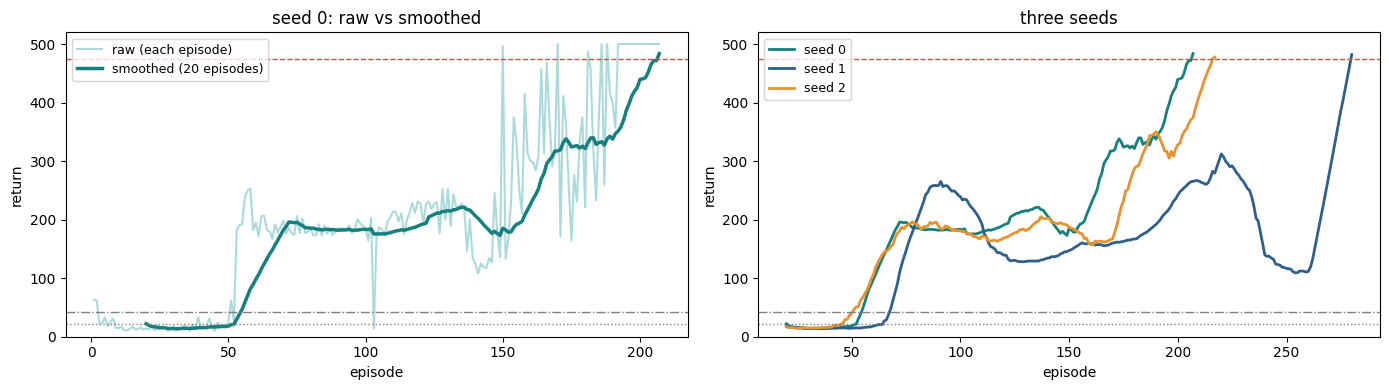

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
r0 = runs[0]["returns"]
ax[0].plot(np.arange(1, len(r0) + 1), r0, color="#2CA6A4", alpha=.4, label="raw (each episode)")
ax[0].plot(np.arange(20, len(r0) + 1), moving(r0), color="#15807E", lw=2.5, label="smoothed (20 episodes)")
ax[0].set_title("seed 0: raw vs smoothed")
for sd, col in zip(runs, ["#15807E", "#2F5F8A", "#E8912D"]):
    ax[1].plot(np.arange(20, len(runs[sd]["returns"]) + 1), moving(runs[sd]["returns"]), color=col, lw=2, label=f"seed {sd}")
ax[1].set_title("three seeds")
for a in ax:
    a.axhline(475, color="#C4553B", ls="--", lw=1); a.axhline(baselines.loc["random", "mean"], color="grey", ls=":", lw=1); a.axhline(baselines.loc["angle rule", "mean"], color="grey", ls="-.", lw=1)
    a.set_xlabel("episode"); a.set_ylabel("return"); a.set_ylim(0, 520); a.legend(loc="upper left", fontsize=9)
plt.tight_layout(); plt.show()

**What to notice:** the seeds reach 475 at about **174, 281 and 382** episodes — the same code, more than a factor of two apart. Each curve also has a long plateau near 190 before it climbs: the agent can balance for a while before it learns to *recover*. Report results as "mean ± spread over seeds", never as one run.

---
# Exercises (graded)

Fill in every `...`. Run the self-check cell after each exercise.

### Exercise 1 · The DQN target (Eq. 18-7)

Write `my_dqn_target(r, s2, terminated, target_net, gamma)` for a **batch**:

**y = r + γ · max over a′ of target_net(s′)[a′] × (1 − terminated)**

Use `torch.no_grad()` — the target is a label, not something to train. Hint: `target_net(s2).max(1).values`.

In [ ]:
def my_dqn_target(r, s2, terminated, target_net, gamma=0.99):
    with torch.no_grad():
        best_next = ...                    # best Q-value of each next state (one number per row)
        return ...

In [ ]:
# ✅ Self-check — Exercise 1
class Fixed(nn.Module):                     # a 'network' that returns fixed Q-values, so the answer can be worked out by hand
    def __init__(self, table): super().__init__(); self.table = torch.tensor(table, dtype=torch.float32)
    def forward(self, s2): return self.table
fake = Fixed([[2, 6], [8, 4], [10, 10]])
y = my_dqn_target(torch.tensor([1., 1., 1.]), torch.zeros(3, 4), torch.tensor([0., 0., 1.]), fake, gamma=0.5)
assert torch.allclose(y, torch.tensor([4., 5., 1.])), f"Expected [4, 5, 1] (1 + 0.5·6, 1 + 0.5·8, terminated → 1), got {y.tolist()}"
net = QNet(); S2 = torch.randn(64, 4); Rb = torch.rand(64); D = (torch.rand(64) < .2).float()
assert torch.allclose(my_dqn_target(Rb, S2, D, net), dqn_target(Rb, S2, D, net)), "Should match the template's dqn_target on a random batch."
print("Exercise 1 ✔  — [4, 5, 1]: the third step terminated, so its target is just r")

### Exercise 2 · Sampling from the replay buffer

Complete `my_sample(buffer, batch_size, rng)`: choose `batch_size` **random** positions among the `len(buffer)` steps stored so far (`rng.integers`), then return five tensors `(S, A, R, S2, D)` taken at those positions from `buffer.S, buffer.A, buffer.R, buffer.S2, buffer.D`.

In [ ]:
def my_sample(buffer, batch_size, rng):
    idx = ...
    return (torch.as_tensor(buffer.S[idx]), ..., ..., ..., ...)

In [ ]:
# ✅ Self-check — Exercise 2
b = ReplayBuffer(100)
for k in range(30): b.add(np.full(4, k, np.float32), k % 2, 1.0, np.full(4, k + 1, np.float32), k == 29)
S, A, R, S2, D = my_sample(b, 16, np.random.default_rng(0))
assert S.shape == (16, 4) and A.shape == (16,) and R.shape == (16,) and S2.shape == (16, 4) and D.shape == (16,), "Shapes should be (16, 4), (16,), (16,), (16, 4), (16,)."
assert torch.all(S[:, 0] < 30), "Only sample among the 30 steps stored so far — use len(buffer), not the capacity (100)."
assert torch.all(S2[:, 0] == S[:, 0] + 1) and torch.all(A == (S[:, 0].long() % 2)), "S, A and S2 must come from the SAME positions."
S_ref = b.sample(16, np.random.default_rng(0))[0]
assert torch.equal(S, S_ref), "With the same rng, your batch should equal the template's."
print("Exercise 2 ✔  — 16 random steps, all five pieces taken from the same positions")

### Exercise 3 · The target network's slow copy

Write `my_soft_update(target_net, online_net, tau)`: for every pair of parameters, **target ← (1 − τ) · target + τ · online**, in place, inside `torch.no_grad()`.

In [ ]:
def my_soft_update(target_net, online_net, tau=0.005):
    with torch.no_grad():
        for pt, po in zip(target_net.parameters(), online_net.parameters()):
            ...

In [ ]:
# ✅ Self-check — Exercise 3
t_net, o_net = QNet(4), QNet(4)
with torch.no_grad():
    for p in t_net.parameters(): p.fill_(0.0)
    for p in o_net.parameters(): p.fill_(1.0)
my_soft_update(t_net, o_net, tau=0.25)
assert all(torch.allclose(p, torch.full_like(p, 0.25)) for p in t_net.parameters()), "After one update with τ = 0.25: 0.75·0 + 0.25·1 = 0.25 everywhere."
my_soft_update(t_net, o_net, tau=0.25)
assert all(torch.allclose(p, torch.full_like(p, 0.4375)) for p in t_net.parameters()), "Second update: 0.75·0.25 + 0.25·1 = 0.4375."
assert all(torch.allclose(p, torch.ones_like(p)) for p in o_net.parameters()), "The ONLINE network must not change."
print("Exercise 3 ✔  — 0 → 0.25 → 0.4375: the target creeps towards the online network")

### Exercise 4 · The four measures (the lecture activity in code)

`table` has one row per checkpoint (episodes 100–500) and one column per seed — the greedy test return. Write `four_measures(table, checkpoints, level=400)` returning a dict:
- `"means"`: the mean over seeds at each checkpoint (a list)
- `"cumulative"`: the sum of those means
- `"first"`: the first checkpoint whose mean ≥ `level` (or `None`)
- `"final_mean"`: the mean at the last checkpoint
- `"final_range"`: `(min, max)` of the last row

In [ ]:
checkpoints = [100, 200, 300, 400, 500]
A = np.array([[20, 30, 40], [150, 210, 240], [480, 450, 420], [500, 500, 470], [500, 490, 480]])
B = np.array([[60, 90, 120], [400, 420, 380], [500, 500, 500], [500, 120, 490], [500, 40, 480]])

In [ ]:
def four_measures(table, checkpoints, level=400):
    means = ...
    first = ...
    return {"means": means, "cumulative": ..., "first": first, "final_mean": ..., "final_range": ...}

In [ ]:
# ✅ Self-check — Exercise 4
mA, mB = four_measures(A, checkpoints), four_measures(B, checkpoints)
assert [round(x) for x in mA["means"]] == [30, 200, 450, 490, 490], f"A's means should be 30, 200, 450, 490, 490 — got {mA['means']}"
assert round(mA["cumulative"]) == 1660 and round(mB["cumulative"]) == 1700, "Cumulative: A 1,660 · B 1,700."
assert mA["first"] == 300 and mB["first"] == 200, "First mean ≥ 400: A at 300, B at 200."
assert round(mA["final_mean"]) == 490 and round(mB["final_mean"]) == 340, "Final means: A 490, B 340."
assert tuple(mA["final_range"]) == (480, 500) and tuple(mB["final_range"]) == (40, 500), "Final ranges: A 480–500, B 40–500."
print("Exercise 4 ✔  — B wins cumulative reward and speed; A wins final performance and stability")
pd.DataFrame({"A": mA, "B": mB}).T

### Exercise 5 · A report-quality plot over seeds

Using `runs` from Part 5, write `plot_seeds(runs)` that draws, on **one** axis:
1. each seed's 20-episode moving average (thin lines),
2. the **mean** of the seeds' moving averages over the episodes that **all** seeds reached (thick line), with a shaded band from the **min** to the **max**,
3. the target (475) and the random baseline.

Then write **one sentence** reading the plot. Return the mean curve (a NumPy array) so the self-check can test it.

In [ ]:
def plot_seeds(runs):
    curves = [moving(r["returns"]) for r in runs.values()]
    L = ...                                   # the length that all seeds reached
    stack = np.array([c[:L] for c in curves])
    mean_curve = ...
    plt.figure(figsize=(10, 4))
    ...
    plt.show()
    return mean_curve

mean_curve = plot_seeds(runs)

In [ ]:
# ✅ Self-check — Exercise 5
L_ref = min(len(moving(r["returns"])) for r in runs.values())
assert len(mean_curve) == L_ref, f"The mean curve should cover only the episodes all seeds reached ({L_ref} points), got {len(mean_curve)}."
ref = np.mean([moving(r["returns"])[:L_ref] for r in runs.values()], axis=0)
assert np.allclose(mean_curve, ref), "mean_curve should be the mean over seeds of the 20-episode moving averages."
print(f"Exercise 5 ✔  — mean curve over {L_ref} episodes; now write your one-sentence reading below")

✍️ **Exercise 5 · my reading of the plot (one sentence):**

*(write here)*

### Exercise 6 · Open-ended: break one stabiliser (choose ONE of a–c, plus d)

Use `train_dqn(seed=0, episodes=300, ...)` and report the four measures (test with `evaluate`).

**(a) No target network:** `use_target=False`. Also plot `q_start` (the predicted Q at the start) on a log scale — compare with `dqn0["q_start"]`. The true value can never exceed 1 / (1 − γ) = 100.

**(b) No replay:** `buffer_size=128` (the buffer only holds the latest batch).

**(c) A different network or learning rate:** `hidden=32` or `lr=1e-3`.

**(d) Write-up (required, at least 3 sentences):** what changed in the four measures, why (use the lecture's words: correlation, moving targets, catastrophic forgetting), and what you would tell someone who wants to deploy this agent.

In [ ]:
# (a), (b) or (c) — your code here
...

✍️ **(d) Write-up:**

*(at least 3 sentences)*

---
## AI-usage disclosure (required)

Did you use an AI assistant (ChatGPT, Claude, Copilot, …) for any part of this lab? If yes: which tool, for which exercise, and what did you change in what it gave you? If no, write "No AI used".

*(write here)*

---
## Submitting
1. Runtime → Restart session and run all — no errors, every self-check ✔ (about 8–10 minutes).
2. File → Download → `.ipynb`.
3. Upload `Lab14_<your_student_id>.ipynb` to the Lab 14 assignment on **MS Teams**.